# 067 — linear svr

LinearSVR; estima o código ordinal, com arredondamento .5 para cima e clipping a 0–15.

**Estado: executado pelo runner; outputs guardados.**

Seleção dentro do treino de desenvolvimento (8.769 linhas), com os mesmos três folds. Validação fixa: 2.193 linhas, já observada anteriormente. Pré-processamento ajustado dentro de cada treino. Sem submissão automática.

067 resultado completo reutilizado após verificar o contexto.
Estado: procedimento concluído; resultados guardados com contexto verificado.
Versões: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}
Duração original (s): 58.190196208001
Notas: Seleção só pela CV no treino. A validação fixa é desenvolvimento e não escolhe parâmetros. Configurações de experiências anteriores já foram selecionadas nestas mesmas linhas; CV pós-seleção não é avaliação independente.
Selecionado: linear_svr
Configuração: {'family': 'linear_svr', 'C': 1.0, 'epsilon': 0.1, 'svd': 0, 'conversion': 'round'}
Diferenças emparelhadas: {'differences': [0.0, 0.0, 0.0], 'mean': 0.0, 'std': 0.0}
Escalões: controlo
Diagnósticos de ajuste: {'seconds': 12.743682250002166, 'warnings': [], 'support_vectors': None, 'train_raw_mae_in_codes': 0.7242666103798211}
MAE em códigos de escalão (não anos): 0.948016415868673
Escalões: selecionad

,configuração,Macro F1 CV,DP,folds
0,linear_svr,0.305704,0.013493,"[0.3209071284147019, 0.2951525494869218, 0.301..."


,modelo,parcela,Macro F1,accuracy
0,controlo,train,0.469240,0.494583
1,controlo,validation,0.320563,0.333789
2,selecionado,train,0.469240,0.494583
3,selecionado,validation,0.320563,0.333789


,classe,precision,recall,F1,support
0,0,0.517241,0.365854,0.428571,41
1,1,0.301887,0.470588,0.367816,34
2,2,0.370370,0.125000,0.186916,80
3,3,0.232143,0.173333,0.198473,75
4,4,0.285714,0.311111,0.297872,90
5,5,0.263959,0.403101,0.319018,129
6,6,0.280899,0.436047,0.341686,172
7,7,0.301887,0.277457,0.289157,173
8,8,0.376147,0.226519,0.282759,181
9,9,0.507042,0.354680,0.417391,203


,classe,precision,recall,F1,support
0,0,0.517241,0.365854,0.428571,41
1,1,0.301887,0.470588,0.367816,34
2,2,0.370370,0.125000,0.186916,80
3,3,0.232143,0.173333,0.198473,75
4,4,0.285714,0.311111,0.297872,90
5,5,0.263959,0.403101,0.319018,129
6,6,0.280899,0.436047,0.341686,172
7,7,0.301887,0.277457,0.289157,173
8,8,0.376147,0.226519,0.282759,181
9,9,0.507042,0.354680,0.417391,203


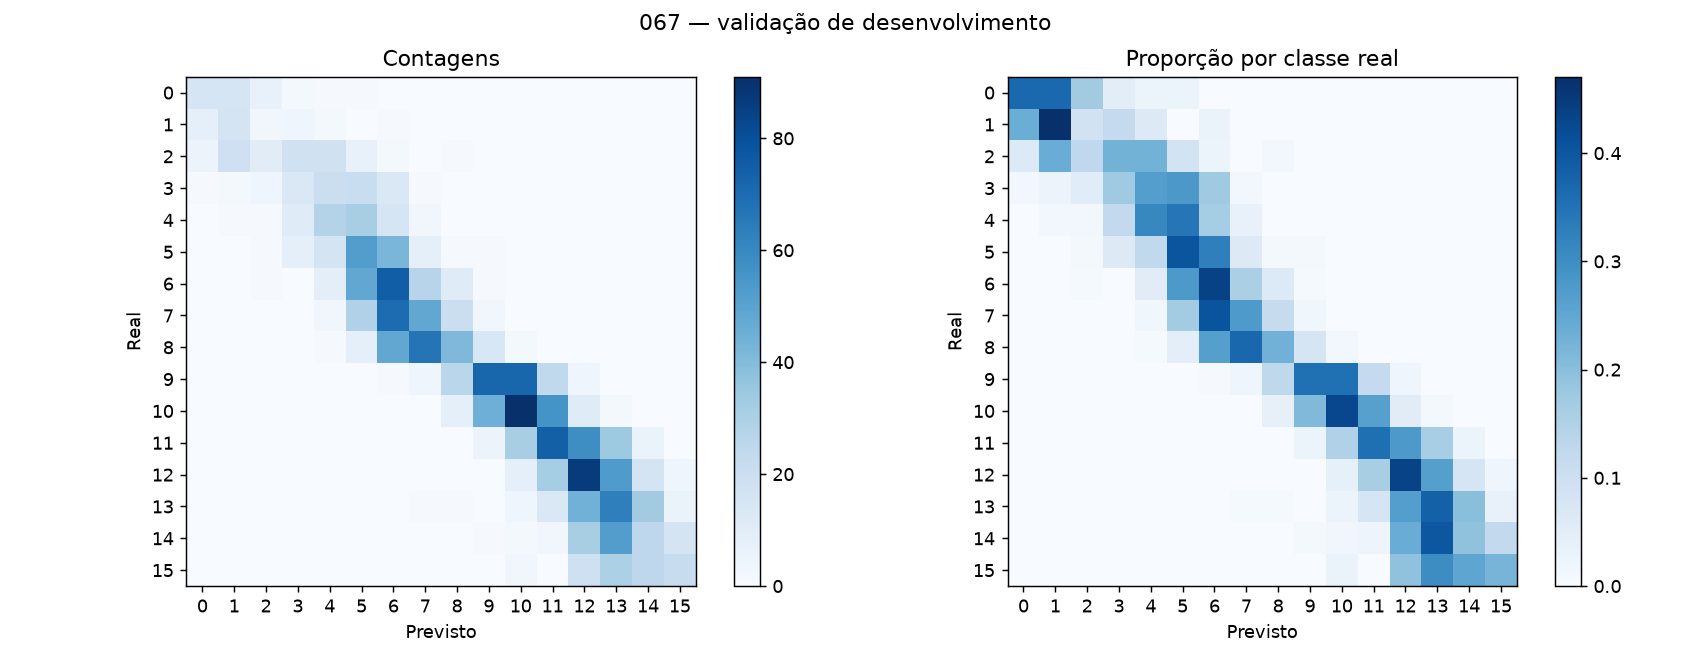

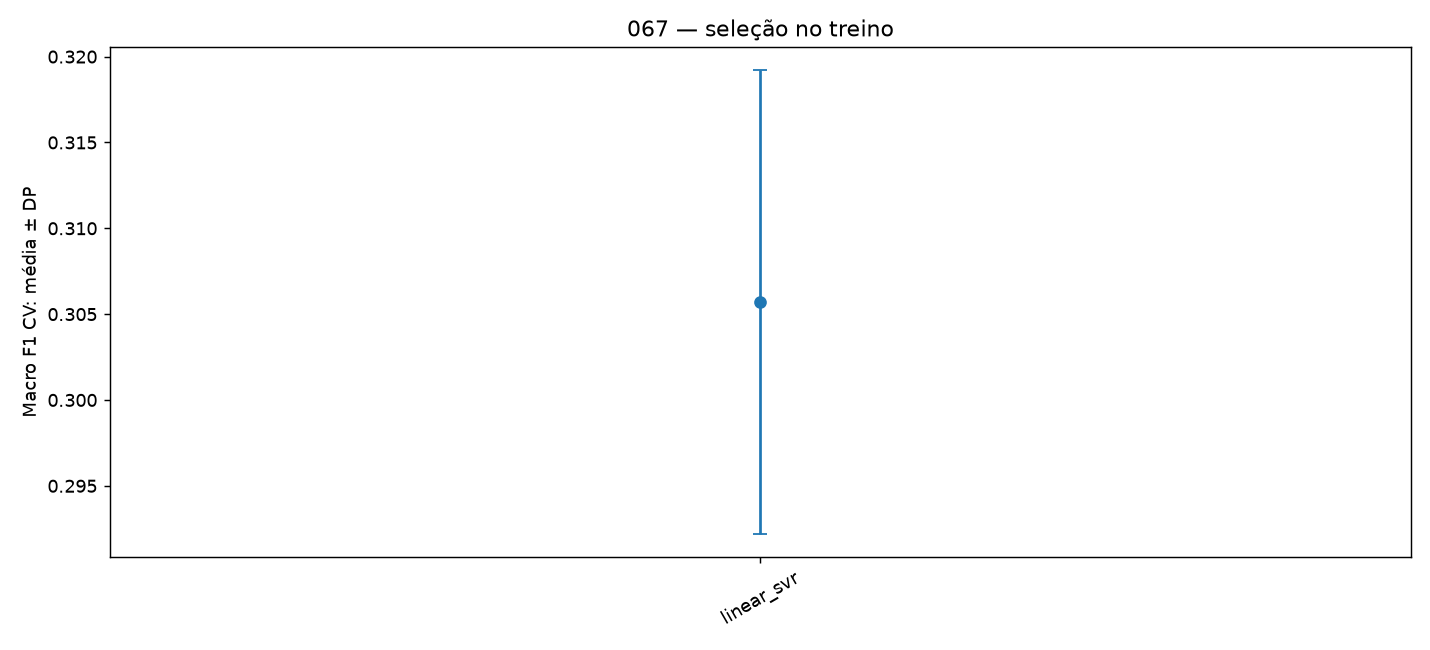

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p/'src/experiments_059_075.py').is_file())
sys.path.insert(0, str(root))
from src.experiments_059_075 import run_experiment
result = run_experiment('067')
print('Estado: procedimento concluído; resultados guardados com contexto verificado.')
print('Versões:', result['context']['base']['versions'])
print('Duração original (s):', result['seconds'])
print('Notas:', result.get('note', ''))
if result.get('candidates'):
    display(pd.DataFrame([{'configuração':r['label'],'Macro F1 CV':r['mean'],'DP':r['std'],'folds':r.get('folds',r.get('scores'))} for r in result['candidates']]))
if result.get('selected'):
    print('Selecionado:', result['selected']['label'])
    print('Configuração:', result['selected']['spec'])
if result.get('paired_cv'):
    print('Diferenças emparelhadas:', result['paired_cv'])
if result.get('fixed'):
    display(pd.DataFrame([{'modelo':name,'parcela':part,'Macro F1':groups[part]['macro_f1'],'accuracy':groups[part]['accuracy']} for name,groups in result['fixed'].items() for part in ['train','validation']]))
    for name, groups in result['fixed'].items():
        print('Escalões:', name)
        display(pd.DataFrame(groups['validation']['per_class']))
        print('Diagnósticos de ajuste:', groups.get('diagnostics'))
        print('MAE em códigos de escalão (não anos):', groups.get('mae_in_class_codes'))
        if 'log_loss' in groups: print('Log loss:',groups['log_loss'])
if result.get('metrics_oof'):
    print('Métricas OOF de desenvolvimento:', result['metrics_oof']['macro_f1'], result['metrics_oof']['accuracy'])
    display(pd.DataFrame(result['metrics_oof']['per_class']))
if 'selected_cases' in result:
    print('Perfis sinalizados:', result['flagged'], '/', result['total'])
    display(pd.DataFrame(result['selected_cases']))
    display(pd.DataFrame(result['by_class']))
if 'categorical_profiles' in result:
    table = pd.DataFrame(result['categorical_profiles'])
    display(table[table.variable.isin(['HATLEVEL','MAINSTAT','HHINCOME','HS1','HS2'])])
    display(pd.DataFrame(result['numeric_profiles']))
    display(pd.DataFrame(result['chronic_diseases']))
for file in sorted((root/'reports').glob('experiencia_067_*.png')):
    display(Image(filename=str(file)))
print('CSV Kaggle:', result.get('submission'))
print('Pontuação Kaggle:', result['kaggle_score'])


## Conclusões locais

- Selecionado internamente: `linear_svr`.
- Macro F1 desenvolvimento: **0.3206**; accuracy: **0.3338**.
- Diferença face ao controlo contemporâneo: **+0.0000**.
- Diferença média nos mesmos folds: **+0.0000**, DP **0.0000**.
- CSV: `submissions/submission_067_linear_svr.csv`. Motivo se não criado: —.

Seleção só pela CV no treino. A validação fixa é desenvolvimento e não escolhe parâmetros. Configurações de experiências anteriores já foram selecionadas nestas mesmas linhas; CV pós-seleção não é avaliação independente.

**Decisão:** preencher depois da revisão; não inferir melhoria pública de uma pequena diferença local.

## Registo manual

- Data:
- CSV submetido (se aplicável):
- Nota Kaggle:
- Conclusão:
- Melhorias a experimentar:

Esta célula e quaisquer notas pessoais não são substituídas pelo script.